# 도구 (Tools)

도구는 에이전트가 외부 시스템과 상호작용할 수 있게 해주는 핵심 구성 요소입니다. API 호출, 데이터베이스 쿼리, 파일 시스템 접근 등 다양한 작업을 수행할 수 있으며, 잘 정의된 입력과 출력을 통해 모델의 기능을 확장합니다.

도구는 호출 가능한 함수와 입력 스키마를 캡슐화합니다. 호환 가능한 채팅 모델에 전달되면, 모델은 도구를 호출할지 여부와 어떤 인수로 호출할지를 자율적으로 결정합니다. 이를 통해 에이전트는 복잡한 작업을 단계별로 수행할 수 있습니다.

> 참고 문서: [LangChain Tools](https://docs.langchain.com/oss/python/langchain/tools.md)

## 환경 설정

도구 튜토리얼을 시작하기 전에 필요한 환경을 설정합니다. `dotenv`를 사용하여 API 키를 로드하고, `langchain_teddynote`의 로깅 기능을 활성화하여 LangSmith에서 도구 호출 과정을 추적할 수 있도록 합니다.

아래 코드는 환경 변수를 로드하고 LangSmith 프로젝트를 설정합니다.

In [1]:
from dotenv import load_dotenv
from langchain_teddynote import logging

# 환경 변수 로드
load_dotenv(override=True)
# 추적을 위한 프로젝트 이름 설정
logging.langsmith("LangChain-V1-Tutorial")

LangSmith 추적을 시작합니다.
[프로젝트명]
LangChain-V1-Tutorial


## 도구 생성

### 기본 도구 정의

도구를 생성하는 가장 간단한 방법은 `@tool` 데코레이터를 사용하는 것입니다. 데코레이터가 적용된 함수는 자동으로 도구로 변환되며, 함수의 docstring이 도구 설명이 됩니다.

**도구 정의 규칙:**
1. `@tool` 데코레이터를 함수에 적용합니다
2. 도구 이름은 함수 이름에서 자동으로 가져옵니다
3. 도구 설명은 함수의 docstring에서 가져옵니다
4. 입력 스키마는 함수의 매개변수와 타입 힌트에서 자동으로 생성됩니다

아래 코드는 데이터베이스 검색 도구를 정의하는 예시입니다.

In [2]:
from langchain.tools import tool


@tool
def search_database(query: str, limit: int = 10) -> str:
    """Search the customer database for records matching the query.

    Args:
        query: Search terms to look for
        limit: Maximum number of results to return
    """
    return f"Found {limit} results for '{query}'"


# 도구 정보 확인
print(f"Tool name: {search_database.name}")
print(f"Tool description: {search_database.description}")

Tool name: search_database
Tool description: Search the customer database for records matching the query.

    Args:
        query: Search terms to look for
        limit: Maximum number of results to return


### 타입 힌트의 중요성

타입 힌트는 도구의 입력 스키마를 정의하므로 필수입니다. 모델은 타입 힌트를 통해 각 매개변수의 타입을 이해하고 올바른 값을 전달합니다. docstring은 모델이 도구의 목적을 이해하는 데 도움이 되므로 정보가 풍부하고 간결해야 합니다.

### 커스텀 도구 이름

기본적으로 도구 이름은 함수 이름에서 가져옵니다. 더 설명적인 이름이 필요한 경우 `@tool("커스텀_이름")` 형식으로 재정의할 수 있습니다. 도구 이름은 모델이 어떤 도구를 호출할지 결정하는 데 사용되므로 명확하고 직관적이어야 합니다.

아래 코드는 커스텀 도구 이름을 설정하는 예시입니다.

In [3]:
@tool("web_search")  # 커스텀 이름
def search(query: str) -> str:
    """Search the web for information."""
    return f"Results for: {query}"


# 도구 이름 확인
print(f"Tool name: {search.name}")  # web_search

Tool name: web_search


### 커스텀 도구 설명

더 명확한 모델 가이드를 위해 자동 생성된 도구 설명을 재정의할 수 있습니다. `description` 매개변수를 사용하면 docstring과 별도로 모델에게 전달되는 설명을 지정할 수 있습니다.

좋은 도구 설명은 도구의 목적, 사용 시점, 예상 결과를 명확히 전달해야 합니다.

아래 코드는 커스텀 도구 설명을 설정하는 예시입니다.

In [9]:
@tool(
    "calculator",
    description="Performs arithmetic calculations. Use this for any math problems.",
)
def calc(expression: str) -> str:
    """Evaluate mathematical expressions."""
    return str(eval(expression))


# 도구 설명 확인
print(f"Tool description: {calc.description}")

Tool description: Performs arithmetic calculations. Use this for any math problems.


---

## Pydantic 모델로 입력 스키마 정의

복잡한 입력 검증이 필요한 경우 Pydantic 모델을 사용하여 명확한 입력 스키마를 정의할 수 있습니다. `args_schema` 매개변수에 Pydantic 모델을 전달하면, 도구 호출 시 자동으로 입력 검증이 수행됩니다.

Pydantic 모델을 사용하면 다음과 같은 이점이 있습니다:
- 타입 검증 및 변환 자동화
- `Literal` 타입을 통한 허용값 제한
- `Field`의 description을 통한 상세한 매개변수 설명

아래 코드는 Pydantic 모델을 사용한 날씨 조회 도구 예시입니다.

In [11]:
from pydantic import BaseModel, Field
from typing import Literal


class WeatherInput(BaseModel):
    """Input for weather queries."""

    location: str = Field(description="City name or coordinates")
    units: Literal["celsius", "fahrenheit"] = Field(
        default="celsius", description="Temperature unit preference"
    )
    include_forecast: bool = Field(default=False, description="Include 5-day forecast")


@tool(args_schema=WeatherInput)
def get_weather(
    location: str, units: str = "celsius", include_forecast: bool = False
) -> str:
    """Get current weather and optional forecast."""
    temp = 22 if units == "celsius" else 72
    result = f"현재 {location} 지역의 날씨는 {temp} {units[0].upper()} 도"
    if include_forecast:
        result += "\n다음 5일 날씨: 맑음"
    return result

In [6]:
# 도구 테스트
print(
    get_weather.invoke(
        {"location": "Seoul", "units": "celsius", "include_forecast": True}
    )
)

현재 Seoul 지역의 날씨는 22 C 도
다음 5일 날씨: 맑음


# Tool에서는 왜 TypedDict 안 쓰고 Pydantic쓰냐!! TypedDict가 좋다며!!
->
퀴즈에서 직접 답해보십시오잉 ㅎㅎ 1주차 복습도 한번 해주시고!

### 입력 검증 오류 예시

아래는 입력 스키마에서 `Literal["celsius", "fahrenheit"]` 타입을 사용했지만, 실제 입력값으로 유효하지 않은 `celsiuss`를 입력했을 때의 오류 예시입니다. Pydantic이 자동으로 입력을 검증하고 오류를 발생시킵니다.

In [7]:
# 도구 테스트
print(
    get_weather.invoke(
        {"location": "Seoul", "units": "celsiuss", "include_forecast": True}
    )
)

ValidationError: 1 validation error for WeatherInput
units
  Input should be 'celsius' or 'fahrenheit' [type=literal_error, input_value='celsiuss', input_type=str]
    For further information visit https://errors.pydantic.dev/2.13/v/literal_error

---

## 컨텍스트 접근

도구는 에이전트 상태, 런타임 컨텍스트 및 장기 메모리에 액세스할 수 있을 때 가장 강력합니다. 이를 통해 도구는 컨텍스트 인식 결정을 내리고, 응답을 개인화하며, 대화 전반에 걸쳐 정보를 유지할 수 있습니다.

`ToolRuntime` 매개변수를 통해 다음 런타임 정보에 액세스할 수 있습니다:

| 속성 | 설명 |
|:---|:---|
| **state** | 실행을 통해 흐르는 변경 가능한 데이터 (메시지, 카운터, 커스텀 필드) |
| **context** | 사용자 ID, 세션 세부 정보 등 불변 구성 정보 |
| **store** | 대화 전반에 걸친 영구 장기 메모리 |
| **stream_writer** | 도구 실행 중 커스텀 업데이트 스트리밍 |
| **config** | 실행을 위한 RunnableConfig |
| **tool_call_id** | 현재 도구 호출의 고유 ID |

### ToolRuntime 사용

`ToolRuntime`을 사용하면 단일 매개변수로 모든 런타임 정보에 액세스할 수 있습니다. 도구 시그니처에 `runtime: ToolRuntime`을 추가하면 LLM에는 노출되지 않고 자동으로 주입됩니다.

`runtime.state`를 통해 현재 그래프 상태에 접근하고, `runtime.context`를 통해 컨텍스트 정보에 접근할 수 있습니다.

아래 코드는 ToolRuntime을 사용하여 상태와 컨텍스트에 접근하는 도구 예시입니다.

In [12]:
from typing import Literal, Optional, Dict, Any, List, Annotated, TypedDict
from pydantic import BaseModel
from langchain.tools import tool, ToolRuntime
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langgraph.checkpoint.memory import InMemorySaver
from langchain_teddynote.messages import stream_graph, invoke_graph
from langgraph.graph.message import add_messages
from langchain.messages import AnyMessage


# 현재 대화 상태 접근
@tool
def summarize_conversation(runtime: ToolRuntime) -> str:
    """Summarize the conversation so far."""
    # state 에서 메시지 접근
    messages = runtime.state.get("messages", [])
    human_msgs = sum(1 for m in messages if m.__class__.__name__ == "HumanMessage")
    ai_msgs = sum(1 for m in messages if m.__class__.__name__ == "AIMessage")
    tool_msgs = sum(1 for m in messages if m.__class__.__name__ == "ToolMessage")
    return f"Conversation has {human_msgs} user messages, {ai_msgs} AI responses, and {tool_msgs} tool results"


@tool
def get_user_preference(
    preference_name: Literal["food", "coding", "sports"],
    runtime: ToolRuntime,  # ToolRuntime 매개변수는 모델에 보이지 않습니다 (자동 주입)
) -> str:
    """Get a user preference value."""

    # context는 state에 저장하지 않고 별도의 context 객체로 inject됨
    preferences = {}
    if getattr(runtime, "context", None) is not None:
        # context dict 내 user_preferences
        preferences = runtime.context.user_preferences or {}
    return preferences.get(preference_name, "Have no information")


class CustomContext(BaseModel):
    user_preferences: Optional[Dict[str, Any]] = None


class CustomState(TypedDict):
    messages: Annotated[List[AnyMessage], add_messages]
    user_preferences: Optional[Dict[str, Any]] = None


# 에이전트 생성
# 다른 모델을 사용하려면 gpt-5.4-mini, claude-sonnet-5 등으로 변경 가능합니다.
model = init_chat_model("gpt-5.4")
agent = create_agent(
    model,
    tools=[summarize_conversation, get_user_preference],
    system_prompt="You are a helpful assistant.",
    # checkpointer=InMemorySaver(),
    context_schema=CustomContext,
    # state_schema=CustomState,
)

config = {"configurable": {"thread_id": "3"}}
inputs = {"messages": [{"role": "user", "content": "내가 좋아하는 음식 알려줘"}]}

invoke_graph(
    agent,
    inputs=inputs,
    config=config,
    context=CustomContext(user_preferences={"food": "pizza"}),
)


🔄 Node: model 🔄
- - - - - - - - - - - - - - - - - - - - - - - - - 
================================== Ai Message ==================================
Tool Calls:
  get_user_preference (call_90aTPx01XDBECzs0LIwWY0gL)
 Call ID: call_90aTPx01XDBECzs0LIwWY0gL
  Args:
    preference_name: food

🔄 Node: tools 🔄
- - - - - - - - - - - - - - - - - - - - - - - - - 
================================= Tool Message =================================
Name: get_user_preference

pizza


/Users/jiho/tech/Agentic-AI-Study-for-DDSI-Lab/.venv/lib/python3.12/site-packages/pydantic/functional_validators.py:835: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `none` - serialized value may not be as expected [field_name='context', input_value=CustomContext(user_preferences={'food': 'pizza'}), input_type=CustomContext])
  function=lambda v, h: h(v), schema=original_schema
/Users/jiho/tech/Agentic-AI-Study-for-DDSI-Lab/.venv/lib/python3.12/site-packages/pydantic/main.py:475: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `none` - serialized value may not be as expected [field_name='context', input_value=CustomContext(user_preferences={'food': 'pizza'}), input_type=CustomContext])
  return self.__pydantic_serializer__.to_python(



🔄 Node: model 🔄
- - - - - - - - - - - - - - - - - - - - - - - - - 
================================== Ai Message ==================================

당신이 좋아하는 음식은 피자예요.


### 에이전트 그래프 시각화

`create_agent`로 생성된 에이전트는 내부적으로 StateGraph 기반의 그래프 구조를 가지고 있습니다. `visualize_graph()`를 사용하면 에이전트의 노드와 엣지 구조를 시각적으로 확인할 수 있어, 실행 흐름을 직관적으로 이해하는 데 도움이 됩니다.

아래 코드는 생성된 에이전트의 그래프 구조를 시각화합니다.

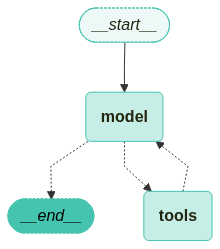

In [13]:
from langchain_teddynote.graphs import visualize_graph

# 에이전트 그래프 구조 시각화
visualize_graph(agent)

### 상태 업데이트

`Command`를 사용하면 도구 내에서 에이전트의 상태를 직접 업데이트하거나 그래프의 실행 흐름을 제어할 수 있습니다. `update` 필드로 상태를 업데이트하고, `goto` 필드로 다음 노드를 지정할 수 있습니다.(배웠던 거 기억나시죠! 아래 코드에서는 goto는 없긴 합니당)

상태 업데이트 시 `ToolMessage`를 포함해야 하며, `tool_call_id`는 `runtime.tool_call_id`에서 가져와야 합니다.

아래 코드는 Command를 사용하여 사용자 이름을 업데이트하는 도구 예시입니다.

In [19]:
from dataclasses import dataclass
from langgraph.types import Command
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain.tools import tool, ToolRuntime
from langchain.messages import AnyMessage, RemoveMessage, ToolMessage
from langchain_teddynote.messages import invoke_graph
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import InMemorySaver
from typing import Annotated, List, Optional, Dict, Any
from pydantic import BaseModel, Field


class CustomContext(BaseModel):
    user_preferences: Optional[Dict[str, Any]] = None


class CustomState(BaseModel):
    user_name: str = Field(default="", description="The user's name")
    messages: Annotated[List[AnyMessage], add_messages]


# User Name 업데이트 도구
@tool
def update_user_name(new_name: str, runtime: ToolRuntime) -> Command:
    """Update the user's name."""
    return Command(
        update={
            "user_name": new_name,  # user_name 상태에 업데이트
            "messages": [
                ToolMessage(
                    content=f"Successfully updated user name to {new_name}",
                    tool_call_id=runtime.tool_call_id,  # runtime 에서 얻어온 tool_call_id 정보를 활용하여 업데이트
                )
            ],
        }
    )


@tool
def clear_messages(runtime: ToolRuntime) -> Command:
    """Clear all messages from the conversation history except the one whose tool_call_id matches the id we don't want to delete."""
    from langchain.messages import AIMessage

    messages = runtime.state.get("messages", [])

    to_remove_messages = []
    tool_call_id = runtime.tool_call_id

    for m in messages:
        if isinstance(m, AIMessage) and getattr(m, "tool_calls", None):
            # Tool Call ID 가 일치하지 않으면 삭제. Tool Call ID 가 일치하면 유지.
            if not any(call.get("id") == tool_call_id for call in m.tool_calls):
                to_remove_messages.append(m)
        else:
            to_remove_messages.append(m)

    removals = [RemoveMessage(id=m.id) for m in to_remove_messages]
    return Command(
        update={
            "messages": removals
            + [
                ToolMessage(
                    content=f"Successfully cleared all previous messages. Total of {len(removals)} deleted messages.",
                    tool_call_id=runtime.tool_call_id,
                )
            ]
        }
    )


# 에이전트 생성
# 다른 모델을 사용하려면 gpt-5.4-mini, claude-sonnet-5 등으로 변경 가능합니다.
model = init_chat_model("gpt-5.4")
agent = create_agent(
    model,
    tools=[update_user_name, clear_messages],
    system_prompt="You are a helpful assistant.",
    state_schema=CustomState,
    context_schema=CustomContext,  # 클래스 자체를 전달 (인스턴스가 아님)
    checkpointer=InMemorySaver(),
)

In [20]:
# 에이전트 실행
config = {"configurable": {"thread_id": "1"}}
invoke_graph(
    agent,
    inputs={"messages": [{"role": "user", "content": "내 이름은 테디야"}]},
    config=config,
)


🔄 Node: model 🔄
- - - - - - - - - - - - - - - - - - - - - - - - - 
================================== Ai Message ==================================
Tool Calls:
  update_user_name (call_iEv3BK2EyNafSQK288yu4tDL)
 Call ID: call_iEv3BK2EyNafSQK288yu4tDL
  Args:
    new_name: 테디

🔄 Node: tools 🔄
- - - - - - - - - - - - - - - - - - - - - - - - - 
user_name:
테디
================================= Tool Message =================================
Name: update_user_name

Successfully updated user name to 테디

🔄 Node: model 🔄
- - - - - - - - - - - - - - - - - - - - - - - - - 
================================== Ai Message ==================================

알겠어, 테디!


In [21]:
invoke_graph(
    agent,
    inputs={"messages": [{"role": "user", "content": "내 이름은 사실 셜리야"}]},
    config=config,
)


🔄 Node: model 🔄
- - - - - - - - - - - - - - - - - - - - - - - - - 
================================== Ai Message ==================================
Tool Calls:
  update_user_name (call_bNjSUebZGWP1BdWQIMZgS1zq)
 Call ID: call_bNjSUebZGWP1BdWQIMZgS1zq
  Args:
    new_name: 셜리

🔄 Node: tools 🔄
- - - - - - - - - - - - - - - - - - - - - - - - - 
user_name:
셜리
================================= Tool Message =================================
Name: update_user_name

Successfully updated user name to 셜리

🔄 Node: model 🔄
- - - - - - - - - - - - - - - - - - - - - - - - - 
================================== Ai Message ==================================

좋아, 이제부터 셜리라고 부를게!


In [22]:
messages = agent.get_state(config).values["messages"]
messages

[HumanMessage(content='내 이름은 테디야', additional_kwargs={}, response_metadata={}, id='4eb31ad5-7ab3-471a-9836-b11b5033607b'),
 AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 20, 'prompt_tokens': 171, 'total_tokens': 191, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5.4-2026-03-05', 'system_fingerprint': None, 'id': 'chatcmpl-EgNNgoItO5Kp53nnZvINuk907CqqO', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1a4ed-03e9-7ed2-8f42-6d9748e34c95-0', tool_calls=[{'name': 'update_user_name', 'args': {'new_name': '테디'}, 'id': 'call_iEv3BK2EyNafSQK288yu4tDL', 'type': 'tool_call'}], invalid_tool_ca

In [23]:
invoke_graph(
    agent,
    inputs={"messages": [{"role": "user", "content": "메시지 전부 삭제해줘"}]},
    config=config,
)


🔄 Node: model 🔄
- - - - - - - - - - - - - - - - - - - - - - - - - 
================================== Ai Message ==================================
Tool Calls:
  clear_messages (call_rJC0tbc3JXm5utTid7O6BfKM)
 Call ID: call_rJC0tbc3JXm5utTid7O6BfKM
  Args:

🔄 Node: tools 🔄
- - - - - - - - - - - - - - - - - - - - - - - - - 
================================ Remove Message ================================


================================ Remove Message ================================


================================ Remove Message ================================


================================ Remove Message ================================


================================ Remove Message ================================


================================ Remove Message ================================


================================ Remove Message ================================


================================ Remove Message ================================


==========

In [24]:
invoke_graph(
    agent,
    inputs={"messages": [{"role": "user", "content": "내 이름이 사실 뭐라고 했지?"}]},
    config=config,
)


🔄 Node: model 🔄
- - - - - - - - - - - - - - - - - - - - - - - - - 
================================== Ai Message ==================================

기록이 지워져서 지금 대화 기준으로는 확인할 수 없어요. 원하시면 지금 알려주신 이름으로 기억해둘게요.


---

### 컨텍스트

`runtime.context`를 통해 사용자 ID, 세션 정보, 애플리케이션별 구성 등 불변 컨텍스트 데이터에 액세스할 수 있습니다. 컨텍스트는 에이전트 호출 시 전달되며, 도구 실행 중에 변경되지 않습니다.

아래 코드는 사용자 컨텍스트를 활용하여 계정 정보를 조회하는 도구 예시입니다.

In [25]:
from dataclasses import dataclass
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain.tools import tool, ToolRuntime

# 사용자 데이터베이스 시뮬레이션
USER_DATABASE = {
    "user123": {
        "name": "Alice Johnson",
        "account_type": "Premium",
        "balance": 5000,
        "email": "alice@example.com",
    },
    "user456": {
        "name": "Bob Smith",
        "account_type": "Standard",
        "balance": 1200,
        "email": "bob@example.com",
    },
}


@dataclass
class UserContext:
    user_id: str


@tool
def get_account_info(runtime: ToolRuntime[UserContext]) -> str:
    """Get the current user's account information."""
    user_id = runtime.context.user_id

    if user_id in USER_DATABASE:
        user = USER_DATABASE[user_id]
        return f"Account holder: {user['name']}\nType: {user['account_type']}\nBalance: ${user['balance']}"
    return "User not found"


# 에이전트 생성
# 다른 모델을 사용하려면 gpt-5.4-mini, claude-sonnet-5 등으로 변경 가능합니다.
model = init_chat_model("gpt-5.4")
agent = create_agent(
    model,
    tools=[get_account_info],
    context_schema=UserContext,
    system_prompt="You are a financial assistant.",
)

# 컨텍스트와 함께 에이전트 실행
result = agent.invoke(
    {"messages": [{"role": "user", "content": "What's my current balance?"}]},
    context=UserContext(user_id="user123"),
)

print(result["messages"][-1].content)

Your current balance is **$5,000**.


### 메모리 (Store)

`runtime.store`를 사용하면 대화 전반에 걸쳐 영구 데이터에 액세스할 수 있습니다. Store는 사용자별 또는 애플리케이션별 데이터를 저장하고 검색하는 장기 메모리 역할을 합니다.

Store는 `get()`, `put()` 메서드를 통해 데이터를 읽고 쓸 수 있으며, 네임스페이스(튜플)와 키를 사용하여 데이터를 구조화합니다.

아래 코드는 Store를 사용하여 사용자 정보를 저장하고 조회하는 도구 예시입니다.

In [26]:
from typing import Any
from langgraph.store.memory import InMemoryStore
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain.tools import tool, ToolRuntime


# 메모리 접근
@tool
def get_user_info(user_id: str, runtime: ToolRuntime) -> str:
    """Look up user info."""
    store = runtime.store
    user_info = store.get(("users",), user_id)
    return str(user_info.value) if user_info else "Unknown user"


# 메모리 업데이트
@tool
def save_user_info(
    user_id: str, user_info: dict[str, Any], runtime: ToolRuntime
) -> str:
    """Save user info."""
    store = runtime.store
    store.put(("users",), user_id, user_info)
    return "Successfully saved user info."


# 스토어와 에이전트 생성
store = InMemoryStore()
# 다른 모델을 사용하려면 gpt-5.4-mini, claude-sonnet-5 등으로 변경 가능합니다.
model = init_chat_model("gpt-5.4")
agent = create_agent(model, tools=[get_user_info, save_user_info], store=store)

# 첫 번째 세션: 사용자 정보 저장
print("=== Saving user info ===")
result1 = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "Save the following user: userid: abc123, name: Foo, age: 25, email: foo@langchain.dev",
            }
        ]
    }
)
print(result1["messages"][-1].content)

# 두 번째 세션: 사용자 정보 가져오기
print("\n=== Getting user info ===")
result2 = agent.invoke(
    {
        "messages": [
            {"role": "user", "content": "Get user info for user with id 'abc123'"}
        ]
    }
)
print(result2["messages"][-1].content)

=== Saving user info ===
Saved user info for `abc123`.

=== Getting user info ===
{"name":"Foo","age":25,"email":"foo@langchain.dev"}


---

## 정리

이 노트북에서는 LangGraph 에이전트에서 도구를 정의하고 활용하는 방법을 학습했습니다.

**핵심 개념 요약:**

| 개념 | 설명 |
|:---|:---|
| **@tool 데코레이터** | 함수를 도구로 변환하며, docstring이 도구 설명이 됩니다 |
| **Pydantic 스키마** | `args_schema`로 복잡한 입력 검증을 자동화합니다 |
| **ToolRuntime** | state, context, store 등 런타임 정보에 접근합니다 |
| **Command** | 도구 내에서 상태 업데이트 및 실행 흐름을 제어합니다 |
| **Store** | 대화 전반에 걸친 영구적인 장기 메모리를 제공합니다 |



---

# 🧩 3주차 퀴즈 ② — Tools

이 노트북에서 배운 내용을 직접 실습해보는 퀴즈입니다. 빈칸(`________`)을 채우고 셀을 실행해서 **"통과! 🎉"** 가 출력되면 성공입니다.

**제출 방법**

1. 퀴즈는 `submissions/본인이름/` 폴더에 미리 들어 있는 **본인 이름이 붙은 노트북**에서 풉니다. (`notebooks/` 원본은 수정 금지!)
2. 각 퀴즈의 빈칸을 채우고 실행 결과를 확인합니다.
3. `week3/본인이름` 브랜치에서 커밋 후 Pull Request를 올립니다. (자세한 방법: 3주차 README)

> ✅ 이번 퀴즈도 **API 키 없이** 전부 풀 수 있습니다. 실제 LLM 대신 아래의 **가짜 모델(`ScriptedToolModel`)** 을 사용합니다.

### 준비: 가짜 모델 `ScriptedToolModel`

아래 셀은 **수정하지 말고 실행만** 하세요.

도구가 실행되려면 모델이 먼저 **"이 도구를 이 인자로 불러줘"** 라는 도구 호출(`tool_calls`)을 만들어야 합니다. 실제 LLM은 매번 다르게 판단하므로 채점이 어렵습니다. 그래서 **정해진 도구를 정해진 인자로 부르도록 대본이 짜인** 가짜 모델을 씁니다.

```
1번째 호출: tool_calls=[{"name": tool_name, "args": tool_args}]   ← 도구 호출
   ↓ (에이전트가 도구 실행 → ToolMessage)
2번째 호출: "[최종답변] (도구 실행 결과)"                            ← 도구 결과를 그대로 보고
```

이 흐름은 2주차 Messages에서 배운 **도구 호출 대화 흐름**(Human → AI(tool_calls) → Tool → AI)과 같습니다.

In [27]:
from typing import Any, Literal, TypedDict

from langchain.agents import create_agent
from langchain.messages import AIMessage, HumanMessage
from langchain.tools import tool
from langchain_core.language_models.chat_models import BaseChatModel
from langchain_core.outputs import ChatGeneration, ChatResult


class ScriptedToolModel(BaseChatModel):
    # 정해진 도구를 정해진 인자로 호출하는 가짜 모델 (API 키 불필요)
    tool_name: str
    tool_args: dict

    def bind_tools(self, tools, **kwargs):
        return self

    def _generate(self, messages, stop=None, run_manager=None, **kwargs):
        last = messages[-1]
        if last.type == "tool":
            # 도구 실행 결과를 받으면 그대로 보고
            message = AIMessage(content=f"[최종답변] {last.content}")
        else:
            # 처음에는 대본대로 도구 호출
            message = AIMessage(
                content="",
                tool_calls=[{"name": self.tool_name, "args": self.tool_args, "id": "call_quiz"}],
            )
        return ChatResult(generations=[ChatGeneration(message=message)])

    @property
    def _llm_type(self) -> str:
        return "scripted"


print("준비 완료!")

준비 완료!


### Q1. `@tool`: 함수가 도구가 되면 LLM은 무엇을 보게 될까?

`@tool`을 붙이면 함수가 도구로 바뀌고, LLM에게는 **이름 · 설명 · 입력 스키마**가 전달됩니다.

- 도구 이름을 `get_forecast`로 **직접 지정**하세요. (힌트: 커스텀 도구 이름)
- `days` 인자의 **타입 힌트**를 채우세요. 타입 힌트가 곧 LLM이 보는 입력 스키마가 됩니다.

In [28]:
@tool ("get_forecast")
def forecast(city: str, days: int = 3) -> str:
    "도시의 일기예보를 조회합니다."
    return f"{city}의 {days}일 예보: 맑음"


print("이름:", forecast.name)
print("설명:", forecast.description)
print("입력 스키마:", forecast.args)

# ---- 자동 채점 ----
assert forecast.name == "get_forecast", "도구 이름은 get_forecast여야 합니다"
assert forecast.description == "도시의 일기예보를 조회합니다.", "설명은 docstring에서 자동으로 가져옵니다"
assert forecast.args["days"]["type"] == "integer", "days는 정수 타입이어야 합니다"
assert forecast.invoke({"city": "서울", "days": 5}) == "서울의 5일 예보: 맑음"
print("통과! 🎉")

이름: get_forecast
설명: 도시의 일기예보를 조회합니다.
입력 스키마: {'city': {'title': 'City', 'type': 'string'}, 'days': {'default': 3, 'title': 'Days', 'type': 'integer'}}
통과! 🎉


### Q2. 도구 입력 스키마: TypedDict vs Pydantic

> **"Tool에서는 왜 TypedDict 안 쓰고 Pydantic 쓰냐!! TypedDict가 좋다며!!"** 에 답해봅시다!

커피 주문 도구의 입력 스키마를 **Pydantic**으로 정의하세요. 사이즈는 `"S"`, `"M"`, `"L"`만 허용하고, 안 주면 기본값 `"M"`입니다.

채점 셀은 같은 내용을 **TypedDict**로 만든 것과 비교해 보여줍니다. 실행 결과를 잘 보고 Q6 주관식에 답해보세요.

In [30]:
from pydantic import BaseModel, Field, ValidationError


class OrderInput(BaseModel):
    menu: str = Field(description="주문할 메뉴 이름")
    size: Literal["S", "M", "L"] = Field(default="M", description="컵 사이즈")


@tool(args_schema=OrderInput)
def order_coffee(menu: str, size: str = "M") -> str:
    "커피를 주문합니다."
    return f"{menu} {size} 사이즈 주문 완료"


# 비교용: 같은 모양을 TypedDict로
class OrderTD(TypedDict):
    menu: str
    size: Literal["S", "M", "L"]


print("TypedDict에 XL 넣기 →", OrderTD(menu="라떼", size="XL")) 

try:
    order_coffee.invoke({"menu": "라떼", "size": "XL"})
    blocked = False
except ValidationError:
    blocked = True
print("Pydantic 도구에 XL 넣기 → 막혔나?", blocked)
print("size 생략 →", order_coffee.invoke({"menu": "아메리카노"}))
print("LLM이 보는 size 설명 →", order_coffee.args["size"])

# ---- 자동 채점 ----
assert blocked, "허용되지 않은 사이즈(XL)는 ValidationError로 막혀야 합니다"
assert order_coffee.invoke({"menu": "아메리카노"}) == "아메리카노 M 사이즈 주문 완료", "기본값은 M이어야 합니다"
assert order_coffee.args["size"]["enum"] == ["S", "M", "L"], "LLM에게 허용값 목록이 전달되어야 합니다"
assert order_coffee.args["size"]["description"] == "컵 사이즈", "Field의 description이 LLM에게 전달되어야 합니다"
print("통과! 🎉")

TypedDict에 XL 넣기 → {'menu': '라떼', 'size': 'XL'}
Pydantic 도구에 XL 넣기 → 막혔나? True
size 생략 → 아메리카노 M 사이즈 주문 완료
LLM이 보는 size 설명 → {'default': 'M', 'description': '컵 사이즈', 'enum': ['S', 'M', 'L'], 'title': 'Size', 'type': 'string'}
통과! 🎉


### Q3. `ToolRuntime`: LLM은 모르는 인자

사용자 선호도를 context에서 꺼내는 도구를 완성하세요.

- `runtime` 인자는 **LLM이 채우지 않고 에이전트가 자동으로 넣어줍니다.** 그래서 LLM에게 전달되는 스키마에는 보이지 않습니다.
- 이진수번 context는 **Pydantic 모델**(= 객체)입니다. TypedDict(= 그냥 dict)였다면 `.get("키")`로 꺼냈겠지만, 객체는 어떻게 꺼낼까요?

In [31]:
from langchain.tools import ToolRuntime


class PrefContext(BaseModel):
    user_preferences: dict = {}


@tool
def get_user_preference(
    preference_name: Literal["food", "coding", "sports"],
    runtime: ToolRuntime[PrefContext],
) -> str:
    "사용자의 선호도를 조회합니다."
    prefs = runtime.context.user_preferences
    return prefs.get(preference_name, "정보 없음")


# 1) LLM에게 보이는 인자 확인
visible_args = list(get_user_preference.tool_call_schema.model_json_schema()["properties"])
print("LLM에게 보이는 인자:", visible_args)

# 2) 에이전트로 실행: 가짜 모델이 preference_name="food"로 도구를 호출
model = ScriptedToolModel(tool_name="get_user_preference", tool_args={"preference_name": "food"})
agent = create_agent(model, tools=[get_user_preference], context_schema=PrefContext)

result = agent.invoke(
    {"messages": [HumanMessage("내가 좋아하는 음식 알려줘")]},
    context=PrefContext(user_preferences={"food": "pizza"}),
)
print(result["messages"][-1].content)

# ---- 자동 채점 ----
assert visible_args == ["preference_name"], "runtime은 LLM에게 보이지 않아야 합니다"
assert result["messages"][-1].content == "[최종답변] pizza", "context의 food 선호도(pizza)를 꺼내야 합니다"
print("통과! 🎉")

LLM에게 보이는 인자: ['preference_name']
[최종답변] pizza
통과! 🎉


### Q4. 도구에서 `Command`로 상태 업데이트하기

도구가 문자열 대신 **`Command`** 를 돌려주면 에이전트의 state를 직접 바꿀 수 있습니다. (2주차 Graph API의 `Command(update=...)` 복습!)

단, 도구 호출에는 **반드시 결과 메시지(`ToolMessage`)가 짝으로** 있어야 합니다. 어떤 도구 호출에 대한 결과인지 연결하는 ID는 어디서 가져올까요? (2주차 퀴즈 ① Q2 복습)

In [ ]:
from typing import Any


from langchain.agents import AgentState
from langchain.messages import ToolMessage
from langgraph.types import Command


class NameState(AgentState):
    user_name: str


@tool
def update_user_name(new_name: str, runtime: ToolRuntime) -> Command:
    "사용자의 이름을 업데이트합니다."
    return Command(  # Command는 "도구의 결과가 그래프의 흐름과 상태에 영향을 줘야 할 때" 쓰는 장치
        update={
            "user_name": new_name,
            "messages": [
                ToolMessage(
                    content=f"이름을 {new_name}(으)로 저장했습니다.",
                    tool_call_id=runtime.tool_call_id,
                )
            ],
        }
    )


model = ScriptedToolModel(tool_name="update_user_name", tool_args={"new_name": "셜리"})
agent = create_agent(model, tools=[update_user_name], state_schema=NameState)

result = agent.invoke({"messages": [HumanMessage("내 이름은 셜리야")]})
print("state의 user_name:", result["user_name"])
print(result["messages"][-1].content)

# ---- 자동 채점 ----
assert result["user_name"] == "셜리", "도구가 state의 user_name을 업데이트해야 합니다"
assert result["messages"][2].tool_call_id == "call_quiz", "ToolMessage는 도구 호출의 id와 연결되어야 합니다"
print("통과! 🎉")

state의 user_name: 셜리
[최종답변] 이름을 셜리(으)로 저장했습니다.
통과! 🎉


### Q5. 개념 확인 (주관식)

이 셀을 **더블클릭**해서 아래 질문에 직접 답을 작성하세요.

1. **"Tool에서는 왜 TypedDict 안 쓰고 Pydantic 쓰는가"**
   - (1주차 복습) TypedDict와 Pydantic의 가장 큰 차이는 무엇인가요? Q2 실행 결과(`XL`)를 근거로 설명해보세요.
   - 1·2주차의 State는 TypedDict로 충분했는데, 도구 입력은 왜 Pydantic이 더 적합할까요? (힌트: 도구 입력값은 **누가** 채우나요? 그리고 `Field(description=...)`은 누구에게 전달되나요?)
   - 답: 
      TypeDict는 받은 입력이 정해진 입력값과 다른지 검증하지 않지만, Pydantic은 정해진 입력값을 받았을 때만 실행된다. 
      State에서는 그래프 안에 있는 노드끼리 정보를 주고받기 때문에 정해진 입력값과 다른 값이 들어갈 일이 없어 TypeDict로 충분하지만, 
      도구 입력은 LLM이 생성하므로 다른 정보가 들어갈 가능성이 있기 때문에 Pydantic이 더 적합하다. 
      Field(description=...) 은 도구 설명의 일부로써, 모델이 호출되는 순간 모델에게 전달된다. 모델은 그 정보를 바탕으로 도구 입력값을 정하고, 이를 Pydantic이 검증한다. 

2. Q3에서 `runtime` 인자는 LLM에게 보이지 않았습니다. 만약 사용자 선호도나 `user_id` 같은 값을 **LLM이 직접 채우는 인자**로 만들었다면 어떤 문제가 생길 수 있을까요? <- 1006 교제 세미나 후반부에 나오는 "ㅇㅇㅇㅇ ㅇㅇ" 문제 ㅎㅎ
   - 답: 
   LLM이 직접 채우면 항상 같은 값을 출력한다는 보장이 없기 때문에, 컨텍스트에 따라 잘못 추측하여 내용이 달라질 수 있다. 특히 user_id를 다르게 입력할 경우 다른 사용자의 정보가 달라질 위험이 존재한다. 
   또 LLM이 지나치게 많은 정보에 주의를 기울이게 되어 컨텍스트 부패 문제가 발생해 성능이 안좋아질 수 있다. 

3. Agents 노트북의 context는 `context.get("prompt_type")`으로, Q3의 context는 `context.user_preferences`로 꺼냈습니다. 왜 꺼내는 방법이 다를까요? (힌트: 각 context는 무엇으로 정의했나요?)
   - 답:
      Agents 노트북에서는 `class Context(TypeDict)`로 정의했다. TypeDict는 딕셔너리기 때문에 get으로 꺼낸다 
      Q3에서는 class `PrefContext(BaseModel)`로 정의했다. `BaseModel`은 객체라서 필드를 속성으로 가져서 .으로 꺼낸다. 

4. **checkpointer**(1주차 메모리)와 **store**는 둘 다 "기억"을 담당합니다. Q5를 근거로 둘의 차이를 설명하고, 각각 어떤 정보를 저장하기에 알맞은지 예를 하나씩 들어보세요.
   - 답: 
      checkpointer는 하나의 대화 안에 state를 단계마다 저장한다. thread_id별로 관리된다. 
      store는 thread와 상관없이 유지되는 장기 기억으로 user_id 별로 관리된다. 